In [1]:
import pandas as pd
df_field = pd.read_excel("/Users/aditiiyer/Documents/Thesis/2024_data.xlsx", skiprows=[0])

In [2]:
print(df_field.columns)

Index(['Name_1', 'Name', 'Date', 'time', 'latitude', 'longitude', 'cloudiness',
       'thufur_hollo_na', 'vertical_water_cm', 'SM1', 'SM2', 'SM3',
       'soil_moisture', 'soil_color', 'soil_texture', 'GreennessIndex',
       'plot_pict_code', 'notes', 'animal_activity', 'soil15cm',
       'Plant_biomass', 'drycore+tray4,8', 'plant fraction+tray4,8',
       'gravel+tray2,9', 'pH', 'EC_µ', 'total_core', 'root2mm', 'coarse2mm',
       'soil_code', 'BD_inc_roots', 'plant_biomass', 'adj_salinity', 'K_mgkg',
       'Pavail_mgkg', 'Navail_mgkg', 'TC_percent', 'TOC_percent',
       'TIC_percent', 'ShannonIndex', 'SpeciesRichness'],
      dtype='object')


In [3]:
df_field = df_field.drop(['Name_1', 'Name', 'cloudiness',
       'thufur_hollo_na', 'vertical_water_cm', 'SM1', 'SM2', 'SM3', 'plot_pict_code', 'notes', 'animal_activity', 'soil15cm',
       'Plant_biomass', 'drycore+tray4,8', 'plant fraction+tray4,8',
       'gravel+tray2,9', 'total_core', 'root2mm', 'coarse2mm',
       'soil_code', 'plant_biomass', 'adj_salinity', 'K_mgkg',
       'Pavail_mgkg', 'Navail_mgkg', 'TC_percent', 'TIC_percent', 'ShannonIndex', 'SpeciesRichness'], axis=1)

In [4]:
df_field.head()

,Date,time,latitude,longitude,soil_moisture,soil_color,soil_texture,GreennessIndex,pH,EC_µ,BD_inc_roots,TOC_percent
0,2024-08-19,17:11:00,33.362800,78.013930,76.20,5Y4/1,sandy clay,0.396047,7.52,490.0,0.320,10.990
1,2024-08-20,06:36:00,33.362720,78.013930,51.00,"2,5Y5/6;2,5Y3/3",sandy clay loam,0.405582,8.14,415.8,0.335,3.217
2,2024-08-20,07:08:00,33.362818,78.014287,63.67,10YR5/6,sandy clay loam,0.364280,9.04,796.6,0.363,7.076
3,2024-08-20,07:38:00,33.362909,78.014341,53.93,10YR5/3,clay,0.367450,9.14,585.1,0.917,6.224
4,2024-08-20,08:01:00,33.362923,78.014530,55.03,10YR3/2,clay loam,0.377370,8.88,4190.0,0.591,6.847


In [5]:
df1 = df_field.copy()

In [6]:
import numpy as np
import pandas as pd

usda_vertices = {
    "Sand": [(100,0,0),(90,10,0),(85,15,0),(100,0,0)],
    "Loamy Sand": [(90,10,0),(85,15,0),(70,30,0),(75,10,15),(90,10,0)],
    "Sandy Loam": [(70,30,0),(52,48,0),(52,28,20),(45,27,28),(50,0,50),(75,10,15),(70,30,0)],
    "Loam": [(52,28,20),(28,44,28),(22,28,50),(40,20,40),(43,34,23),(45,27,28),(52,28,20)],
    "Silt Loam": [(20,80,0),(0,100,0),(0,88,12),(8,42,50),(28,22,50),(28,44,28),(52,28,20),(43,34,23),(40,20,40),(22,28,50),(20,80,0)],
    "Silt": [(0,100,0),(0,88,12),(0,100,0)],
    "Sandy Clay Loam": [(45,27,28),(43,34,23),(65,35,0),(52,48,0),(52,28,20),(45,27,28)],
    "Clay Loam": [(28,44,28),(22,28,50),(40,20,40),(47,13,40),(55,25,20),(43,34,23),(28,44,28)],
    "Silty Clay Loam": [(28,22,50),(22,28,50),(0,50,50),(0,60,40),(8,42,50),(28,22,50)],
    "Sandy Clay": [(65,35,0),(55,45,0),(45,35,20),(55,25,20),(65,35,0)],
    "Silty Clay": [(0,60,40),(0,88,12),(8,42,50),(0,60,40)],
    "Clay": [(55,45,0),(45,35,20),(40,20,40),(47,13,40),(55,25,20),(55,45,0)]
}

def ternary_centroid(coords):
    arr = np.array(coords, dtype=float)
    c = arr.mean(axis=0)
    s = c.sum()
    if s != 0:
        c = c / s * 100
    return tuple(c)

centroids = {k: ternary_centroid(v) for k, v in usda_vertices.items()}

centroid_df = pd.DataFrame.from_dict(
    centroids,
    orient="index",
    columns=["sand_centroid","silt_centroid","clay_centroid"]
)

# soil_texture column must match centroid keys exactly; normalize if needed
df_field["soil_texture"] = df_field["soil_texture"].str.strip().str.title()

df = df_field.merge(
    centroid_df,
    left_on="soil_texture",
    right_index=True,
    how="left"
)

df1 = df.drop(columns=["soil_texture"])


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/ternary/plotting.py:148: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  ax.scatter(xs, ys, vmin=vmin, vmax=vmax, **kwargs)


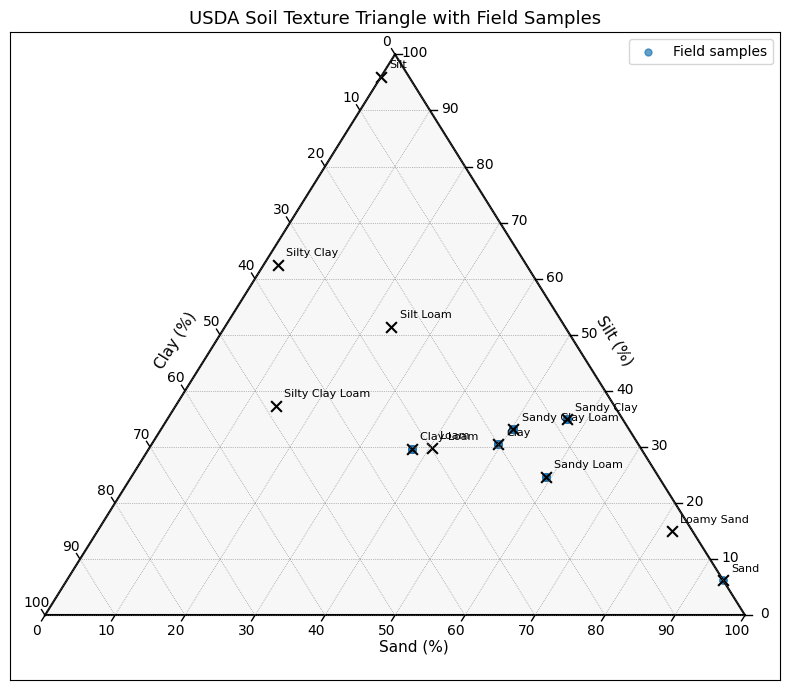

In [7]:
import ternary
import matplotlib.pyplot as plt

points = df[["sand_centroid", "silt_centroid", "clay_centroid"]].dropna().values.tolist()

fig, tax = ternary.figure(scale=100)
fig.set_size_inches(8, 7)

tax.boundary(linewidth=1.5)
tax.gridlines(multiple=10, color="gray", linewidth=0.5)

tax.left_axis_label("Clay (%)", fontsize=11)
tax.right_axis_label("Silt (%)", fontsize=11)
tax.bottom_axis_label("Sand (%)", fontsize=11, offset=-0.10)

tax.scatter(
    points,
    marker="o",
    color="tab:blue",
    s=25,
    alpha=0.7,
    label="Field samples"
)

for name, (sand, silt, clay) in centroids.items():
    tax.scatter(
        [(sand, silt, clay)],
        marker="x",
        color="black",
        s=60
    )

    tax.annotate(
        name,
        (sand, silt, clay),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

tax.ticks(axis="lbr", multiple=10, linewidth=1)
tax.clear_matplotlib_ticks()
tax.legend(loc="upper right")
tax.set_title("USDA Soil Texture Triangle with Field Samples", fontsize=13)

plt.tight_layout()
plt.show()

In [8]:
import re
import pandas as pd

def parse_munsell_hvc(x):
    if pd.isna(x):
        return (None, None, None)
    s = str(x).replace(',', '.')
    s = s.split(';')[0].strip()
    m = re.match(r'([0-9\.]+)([A-Z]+)([0-9\.]+)/([0-9\.]+)', s)
    if m:
        hue_num = float(m.group(1))
        hue_sym = m.group(2)
        val = float(m.group(3))
        chroma = float(m.group(4))
        hue_map = {'R':0,'YR':10,'Y':20,'GY':30,'G':40,'BG':50,'B':60,'PB':70,'P':80,'RP':90}
        h = hue_num + hue_map.get(hue_sym, 0)
        return (h, val, chroma)
    return (None, None, None)

df1 = df1.copy()
df1[['H','V','C']] = df1['soil_color'].apply(parse_munsell_hvc).apply(pd.Series)


In [9]:
df1.head()

,Date,time,latitude,longitude,soil_moisture,soil_color,GreennessIndex,pH,EC_µ,BD_inc_roots,TOC_percent,sand_centroid,silt_centroid,clay_centroid,H,V,C
0,2024-08-19,17:11:00,33.362800,78.013930,76.20,5Y4/1,0.396047,7.52,490.0,0.320,10.990,57.000000,35.000000,8.000000,25.0,4.0,1.0
1,2024-08-20,06:36:00,33.362720,78.013930,51.00,"2,5Y5/6;2,5Y3/3",0.405582,8.14,415.8,0.335,3.217,50.333333,33.166667,16.500000,22.5,5.0,6.0
2,2024-08-20,07:08:00,33.362818,78.014287,63.67,10YR5/6,0.364280,9.04,796.6,0.363,7.076,50.333333,33.166667,16.500000,20.0,5.0,6.0
3,2024-08-20,07:38:00,33.362909,78.014341,53.93,10YR5/3,0.367450,9.14,585.1,0.917,6.224,49.500000,30.500000,20.000000,20.0,5.0,3.0
4,2024-08-20,08:01:00,33.362923,78.014530,55.03,10YR3/2,0.377370,8.88,4190.0,0.591,6.847,37.571429,29.714286,32.714286,20.0,3.0,2.0


Model with Field Variables

In [10]:
X_test = df1.drop(['Date', 'time','soil_color'], axis=1)
X_test.head()

,latitude,longitude,soil_moisture,GreennessIndex,pH,EC_µ,BD_inc_roots,TOC_percent,sand_centroid,silt_centroid,clay_centroid,H,V,C
0,33.362800,78.013930,76.20,0.396047,7.52,490.0,0.320,10.990,57.000000,35.000000,8.000000,25.0,4.0,1.0
1,33.362720,78.013930,51.00,0.405582,8.14,415.8,0.335,3.217,50.333333,33.166667,16.500000,22.5,5.0,6.0
2,33.362818,78.014287,63.67,0.364280,9.04,796.6,0.363,7.076,50.333333,33.166667,16.500000,20.0,5.0,6.0
3,33.362909,78.014341,53.93,0.367450,9.14,585.1,0.917,6.224,49.500000,30.500000,20.000000,20.0,5.0,3.0
4,33.362923,78.014530,55.03,0.377370,8.88,4190.0,0.591,6.847,37.571429,29.714286,32.714286,20.0,3.0,2.0


In [11]:
X_test.to_csv("/Users/aditiiyer/Documents/Thesis/outlier_data_field.csv", index=False )

In [12]:
import pandas as pd
import numpy as np

df_clean = X_test.copy()

threshold = df_clean["TOC_percent"].quantile(0.85)

df_filtered = df_clean[df_clean["TOC_percent"] <= threshold]

print("Original size:", df_clean.shape)
print("Filtered size:", df_filtered.shape)
print("90th percentile threshold:", threshold)


Original size: (93, 14)
Filtered size: (76, 14)
90th percentile threshold: 15.311999999999987


In [13]:
from sklearn.model_selection import train_test_split, KFold

X1 = df_filtered.drop(['TOC_percent'], axis=1)
y1 = df_filtered['TOC_percent']

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

In [14]:
X1.head()

,latitude,longitude,soil_moisture,GreennessIndex,pH,EC_µ,BD_inc_roots,sand_centroid,silt_centroid,clay_centroid,H,V,C
0,33.362800,78.013930,76.20,0.396047,7.52,490.0,0.320,57.000000,35.000000,8.000000,25.0,4.0,1.0
1,33.362720,78.013930,51.00,0.405582,8.14,415.8,0.335,50.333333,33.166667,16.500000,22.5,5.0,6.0
2,33.362818,78.014287,63.67,0.364280,9.04,796.6,0.363,50.333333,33.166667,16.500000,20.0,5.0,6.0
3,33.362909,78.014341,53.93,0.367450,9.14,585.1,0.917,49.500000,30.500000,20.000000,20.0,5.0,3.0
4,33.362923,78.014530,55.03,0.377370,8.88,4190.0,0.591,37.571429,29.714286,32.714286,20.0,3.0,2.0


In [15]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

class SparrowSearchOptimizer:
    def __init__(self, obj_func, lb, ub, pop_size=25, max_iter=30):
        self.obj = obj_func
        self.lb = np.array(lb)
        self.ub = np.array(ub)
        self.dim = len(lb)
        self.pop = pop_size
        self.it = max_iter

    def optimize(self):
        Xp = np.random.uniform(self.lb, self.ub, (self.pop, self.dim))
        f = np.array([self.obj(x) for x in Xp])
        best_idx = np.argmin(f)
        best = Xp[best_idx].copy()
        best_f = f[best_idx]
        for t in range(self.it):
            r = np.random.rand()
            for i in range(self.pop):
                if i < self.pop * 0.2:
                    Xp[i] = Xp[i] * np.exp(-(i/(r+1e-9)))
                else:
                    Xp[i] = Xp[i] + np.random.randn(self.dim) * 0.01
                Xp[i] = np.clip(Xp[i], self.lb, self.ub)
            f = np.array([self.obj(x) for x in Xp])
            idx2 = np.argmin(f)
            if f[idx2] < best_f:
                best = Xp[idx2].copy()
                best_f = f[idx2]
        return best, best_f

def objective(params):
    n_estimators = int(params[0])
    max_depth = int(params[1])
    min_split = int(params[2])
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_split,
        random_state=42
    )
    model.fit(X_train1, y_train1)
    preds1 = model.predict(X_test1)
    return mean_absolute_error(y_test1, preds1)

lb1 = [50, 3, 2]
ub1 = [400, 20, 10]

ssa = SparrowSearchOptimizer(objective, lb1, ub1, pop_size=25, max_iter=25)
best_params1, best_score1 = ssa.optimize()

best_model1 = RandomForestRegressor(
    n_estimators=int(best_params1[0]),
    max_depth=int(best_params1[1]),
    min_samples_split=int(best_params1[2]),
    oob_score=True,
    bootstrap=True,
    random_state=42
)

best_model1.fit(X_train1, y_train1)
pred_test1 = best_model1.predict(X_test1)

In [16]:
oob_score = best_model1.oob_score_
print(f'Out-of-Bag Score: {oob_score}')

Out-of-Bag Score: 0.11798633990521057


In [17]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_model1.fit(X_train1, y_train1)

pred_train1 = best_model1.predict(X_train1)
pred_test1 = best_model1.predict(X_test1)

r2_train = r2_score(y_train1, pred_train1)
r2_test = r2_score(y_test1, pred_test1)

mae = mean_absolute_error(y_test1, pred_test1)
rmse = np.sqrt(mean_squared_error(y_test1, pred_test1))

print("R2 train:", r2_train)
print("R2 test:", r2_test)
print("MAE:", mae)
print("RMSE:", rmse)


R2 train: 0.7702521433062754
R2 test: 0.36217871424847525
MAE: 2.196673602960149
RMSE: 2.6898746384897856


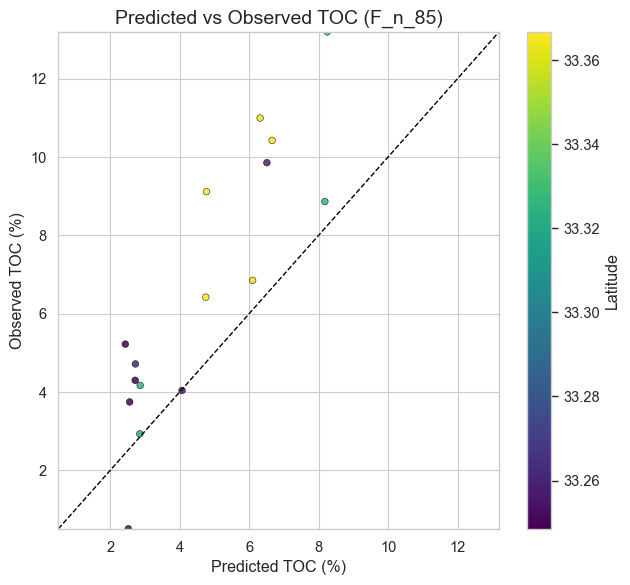

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

plot_df = pd.DataFrame({
    "Observed TOC (%)": y_test1.values,
    "Predicted TOC (%)": pred_test1,
    "Latitude": X_test1['latitude'].values
})

plot_df["Residual"] = plot_df["Observed TOC (%)"] - plot_df["Predicted TOC (%)"]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(6.5, 6))

norm = Normalize(
    vmin=plot_df["Latitude"].min(),
    vmax=plot_df["Latitude"].max()
)

sns.scatterplot(
    data=plot_df,
    x="Predicted TOC (%)",
    y="Observed TOC (%)",
    hue="Latitude",
    palette="viridis",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
    legend=False,
    ax=ax
)

lims = [
    plot_df[["Observed TOC (%)", "Predicted TOC (%)"]].min().min(),
    plot_df[["Observed TOC (%)", "Predicted TOC (%)"]].max().max()
]

ax.plot(lims, lims, linestyle="--", color="black", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_title("Predicted vs Observed TOC (F_n_85)", fontsize=14)
ax.set_xlabel("Predicted TOC (%)")
ax.set_ylabel("Observed TOC (%)")

sm = ScalarMappable(norm=norm, cmap="viridis")
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Latitude")

plt.tight_layout()
plt.show()

Model without dropping outliers

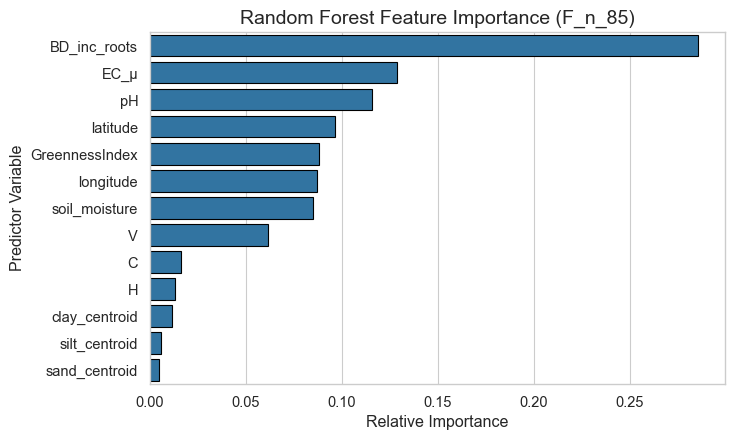

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

imp_df = pd.DataFrame({
    "Feature": X1.columns,
    "Importance": best_model1.feature_importances_
})

imp_df = (
    imp_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(7.5, max(4, 0.35 * len(imp_df))))

sns.barplot(
    data=imp_df,
    x="Importance",
    y="Feature",
    color="tab:blue",
    edgecolor="black",
    ax=ax
)

ax.set_title("Random Forest Feature Importance (F_n_85)", fontsize=14)
ax.set_xlabel("Relative Importance")
ax.set_ylabel("Predictor Variable")

plt.tight_layout()
plt.show()

In [20]:
X_test = pd.read_csv("/Users/aditiiyer/Documents/Thesis/outlier_data_field.csv")

In [21]:
X_test.dropna(inplace=True)

In [22]:
from sklearn.model_selection import train_test_split, KFold

X2 = X_test.drop(['TOC_percent'], axis=1)
y2 = X_test['TOC_percent']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

In [23]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

class SparrowSearchOptimizer:
    def __init__(self, obj_func, lb, ub, pop_size=25, max_iter=30):
        self.obj = obj_func
        self.lb = np.array(lb)
        self.ub = np.array(ub)
        self.dim = len(lb)
        self.pop = pop_size
        self.it = max_iter

    def optimize(self):
        Xp = np.random.uniform(self.lb, self.ub, (self.pop, self.dim))
        f = np.array([self.obj(x) for x in Xp])
        best_idx = np.argmin(f)
        best = Xp[best_idx].copy()
        best_f = f[best_idx]
        for t in range(self.it):
            r = np.random.rand()
            for i in range(self.pop):
                if i < self.pop * 0.2:
                    Xp[i] = Xp[i] * np.exp(-(i/(r+1e-9)))
                else:
                    Xp[i] = Xp[i] + np.random.randn(self.dim) * 0.01
                Xp[i] = np.clip(Xp[i], self.lb, self.ub)
            f = np.array([self.obj(x) for x in Xp])
            idx2 = np.argmin(f)
            if f[idx2] < best_f:
                best = Xp[idx2].copy()
                best_f = f[idx2]
        return best, best_f

def objective(params):
    n_estimators = int(params[0])
    max_depth = int(params[1])
    min_split = int(params[2])
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_split,
        random_state=42
    )
    model.fit(X_train2, y_train2)
    preds2 = model.predict(X_test2)
    return mean_absolute_error(y_test2, preds2)

lb2 = [50, 3, 2]
ub2 = [400, 20, 10]

ssa = SparrowSearchOptimizer(objective, lb2, ub2, pop_size=25, max_iter=25)
best_params2, best_score2 = ssa.optimize()

best_model2 = RandomForestRegressor(
    n_estimators=int(best_params2[0]),
    max_depth=int(best_params2[1]),
    min_samples_split=int(best_params2[2]),
    oob_score=True,
    bootstrap=True,
    random_state=42
)

best_model2.fit(X_train2, y_train2)
pred_test2 = best_model2.predict(X_test2)

In [24]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_model2.fit(X_train2, y_train2)

pred_train2 = best_model2.predict(X_train2)
pred_test2 = best_model2.predict(X_test2)

r2_train = r2_score(y_train2, pred_train2)
r2_test = r2_score(y_test2, pred_test2)

mae = mean_absolute_error(y_test2, pred_test2)
rmse = np.sqrt(mean_squared_error(y_test2, pred_test2))

print("R2 train:", r2_train)
print("R2 test:", r2_test)
print("MAE:", mae)
print("RMSE:", rmse)

R2 train: 0.7786098060660193
R2 test: -0.8586089130543195
MAE: 3.7147290366020904
RMSE: 5.15837306888232


In [25]:
oob_score = best_model2.oob_score_
print(f'Out-of-Bag Score: {oob_score}')

Out-of-Bag Score: 0.36140545891447784


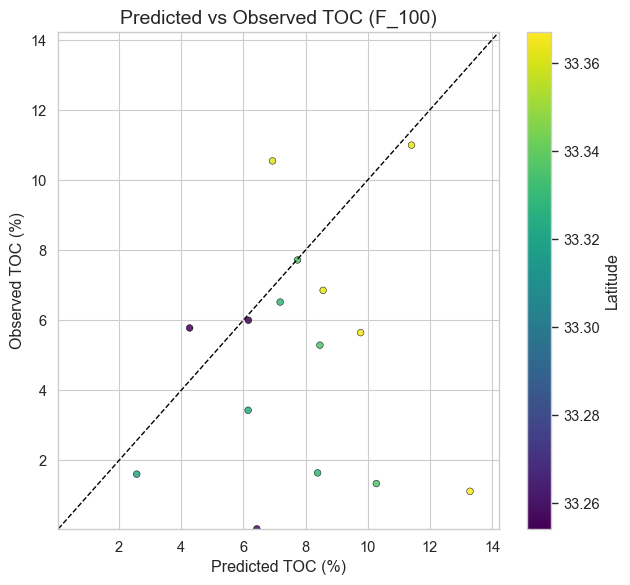

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

plot_df = pd.DataFrame({
    "Observed TOC (%)": y_test2.values,
    "Predicted TOC (%)": pred_test2,
    "Latitude": X_test2['latitude'].values
})

plot_df["Residual"] = plot_df["Observed TOC (%)"] - plot_df["Predicted TOC (%)"]

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(6.5, 6))

norm = Normalize(
    vmin=plot_df["Latitude"].min(),
    vmax=plot_df["Latitude"].max()
)

sns.scatterplot(
    data=plot_df,
    x="Predicted TOC (%)",
    y="Observed TOC (%)",
    hue="Latitude",
    palette="viridis",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
    legend=False,
    ax=ax
)

lims = [
    plot_df[["Observed TOC (%)"]].min().min(),
    plot_df[["Observed TOC (%)"]].max().max()
]

ax.plot(lims, lims, linestyle="--", color="black", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_title("Predicted vs Observed TOC (F_100)", fontsize=14)
ax.set_xlabel("Predicted TOC (%)")
ax.set_ylabel("Observed TOC (%)")

sm = ScalarMappable(norm=norm, cmap="viridis")
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Latitude")

plt.tight_layout()
plt.show()

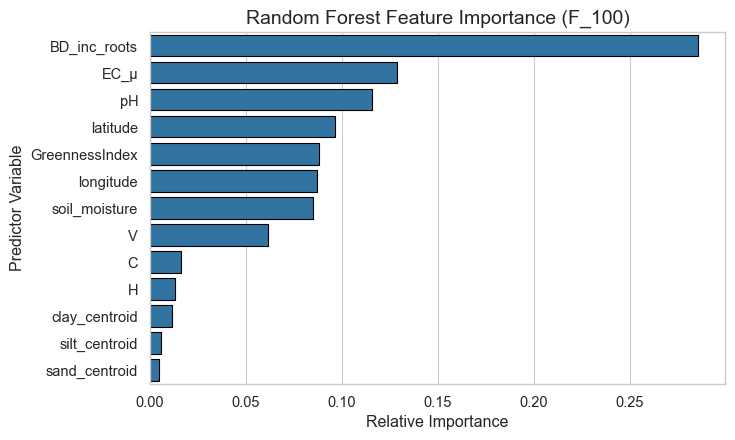

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

imp_df = pd.DataFrame({
    "Feature": X2.columns,
    "Importance": best_model1.feature_importances_
})

imp_df = (
    imp_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(7.5, max(4, 0.35 * len(imp_df))))

sns.barplot(
    data=imp_df,
    x="Importance",
    y="Feature",
    color="tab:blue",
    edgecolor="black",
    ax=ax
)

ax.set_title("Random Forest Feature Importance (F_100)", fontsize=14)
ax.set_xlabel("Relative Importance")
ax.set_ylabel("Predictor Variable")

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np

output_df = df_filtered.loc[X_test1.index, ["latitude", "longitude", "TOC_percent"]].copy()

output_df = output_df.rename(columns={"TOC_percent": "Observed_TOC"})

output_df["Predicted_TOC"] = pred_test1
output_df["Error"] = output_df["Observed_TOC"] - output_df["Predicted_TOC"]
output_df["Absolute_Error"] = np.abs(output_df["Error"])

output_df = output_df.reset_index(drop=True)

output_df

,latitude,longitude,Observed_TOC,Predicted_TOC,Error,Absolute_Error
0,33.362923,78.01453,6.847,6.096785,0.750215,0.750215
1,33.325870,78.03692,4.164,2.859265,1.304735,1.304735
2,33.365900,78.01350,6.416,4.747756,1.668244,1.668244
3,33.362800,78.01393,10.990,6.312421,4.677579,4.677579
4,33.322040,78.03738,2.925,2.848441,0.076559,0.076559
5,33.248520,78.05954,5.218,2.430585,2.787415,2.787415
6,33.260170,78.05237,4.713,2.720281,1.992719,1.992719
7,33.249360,78.05969,3.742,2.555664,1.186336,1.186336
8,33.248600,78.05903,4.295,2.714796,1.580204,1.580204
9,33.329360,78.03653,13.190,8.244723,4.945277,4.945277


In [29]:
output_df.to_csv(
    "/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_F_n_75.csv",
    index=False
)

In [30]:
import pandas as pd
import numpy as np

output_df1 = df_filtered.loc[X_test2.index, ["latitude", "longitude", "TOC_percent"]].copy()

output_df1 = output_df1.rename(columns={"TOC_percent": "Observed_TOC"})

output_df1["Predicted_TOC"] = pred_test2
output_df1["Error"] = output_df1["Observed_TOC"] - output_df1["Predicted_TOC"]
output_df1["Absolute_Error"] = np.abs(output_df1["Error"])

output_df1 = output_df1.reset_index(drop=True)

output_df1

,latitude,longitude,Observed_TOC,Predicted_TOC,Error,Absolute_Error
0,33.335820,78.03325,5.284,8.458232,-3.174232,3.174232
1,33.362800,78.01393,10.990,11.405382,-0.415382,0.415382
2,33.361780,78.01774,10.540,6.933662,3.606338,3.606338
3,33.335510,78.03239,1.336,10.272639,-8.936639,8.936639
4,33.367100,78.01224,1.115,13.286214,-12.171214,12.171214
5,33.336200,78.03418,7.713,7.736517,-0.023517,0.023517
6,33.364100,78.01310,7.329,16.455745,-9.126745,9.126745
7,33.321870,78.03676,1.604,2.565915,-0.961915,0.961915
8,33.362923,78.01453,6.847,8.562434,-1.715434,1.715434
9,33.365510,78.01299,5.640,9.766959,-4.126959,4.126959


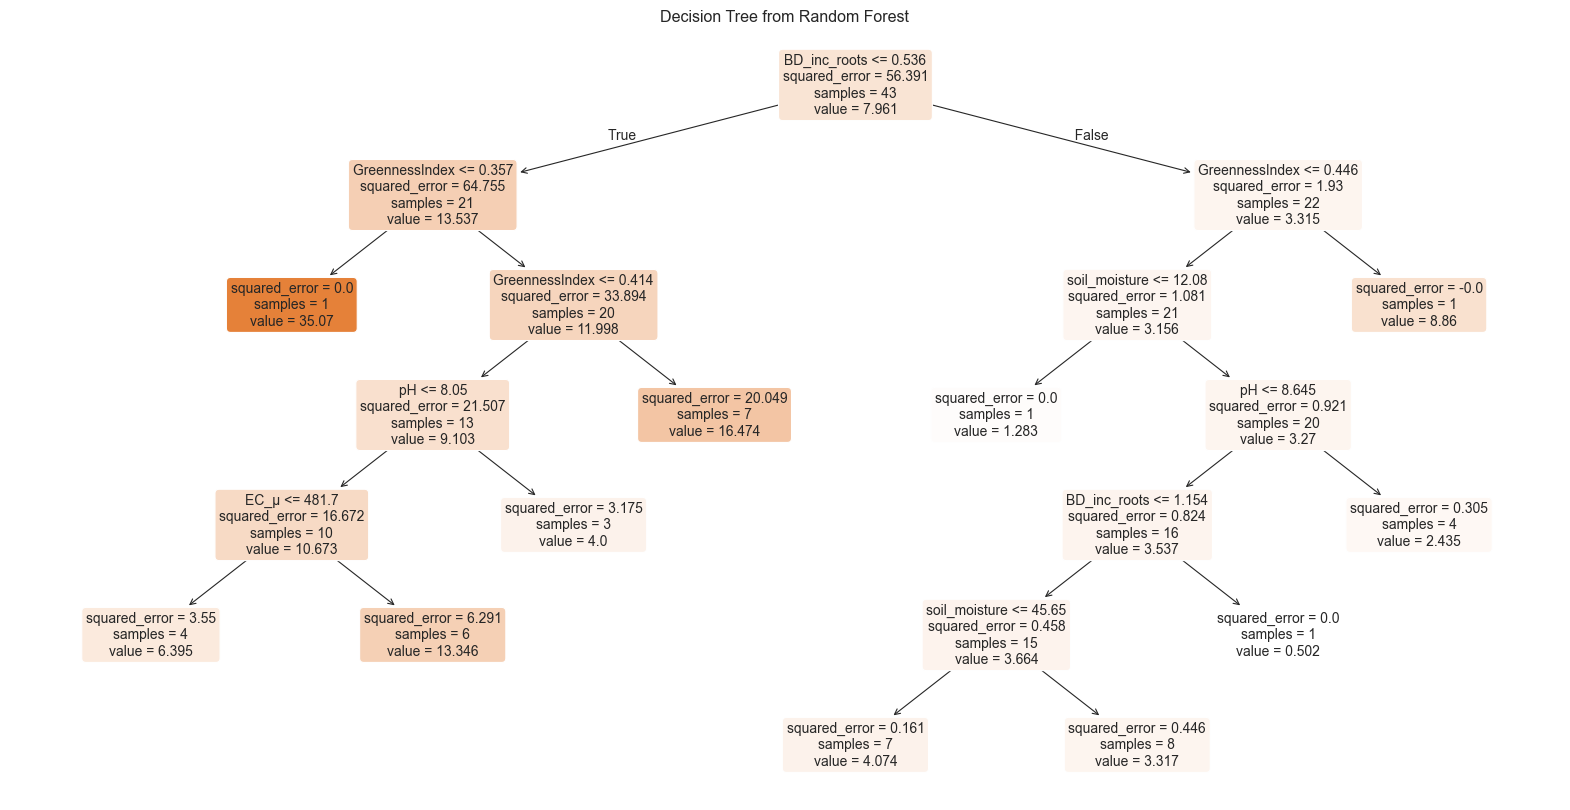

In [31]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_to_plot = best_model2.estimators_[3]

plt.figure(figsize=(20, 10))
plot_tree(tree_to_plot, feature_names=X_train2.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree from Random Forest")
plt.show()

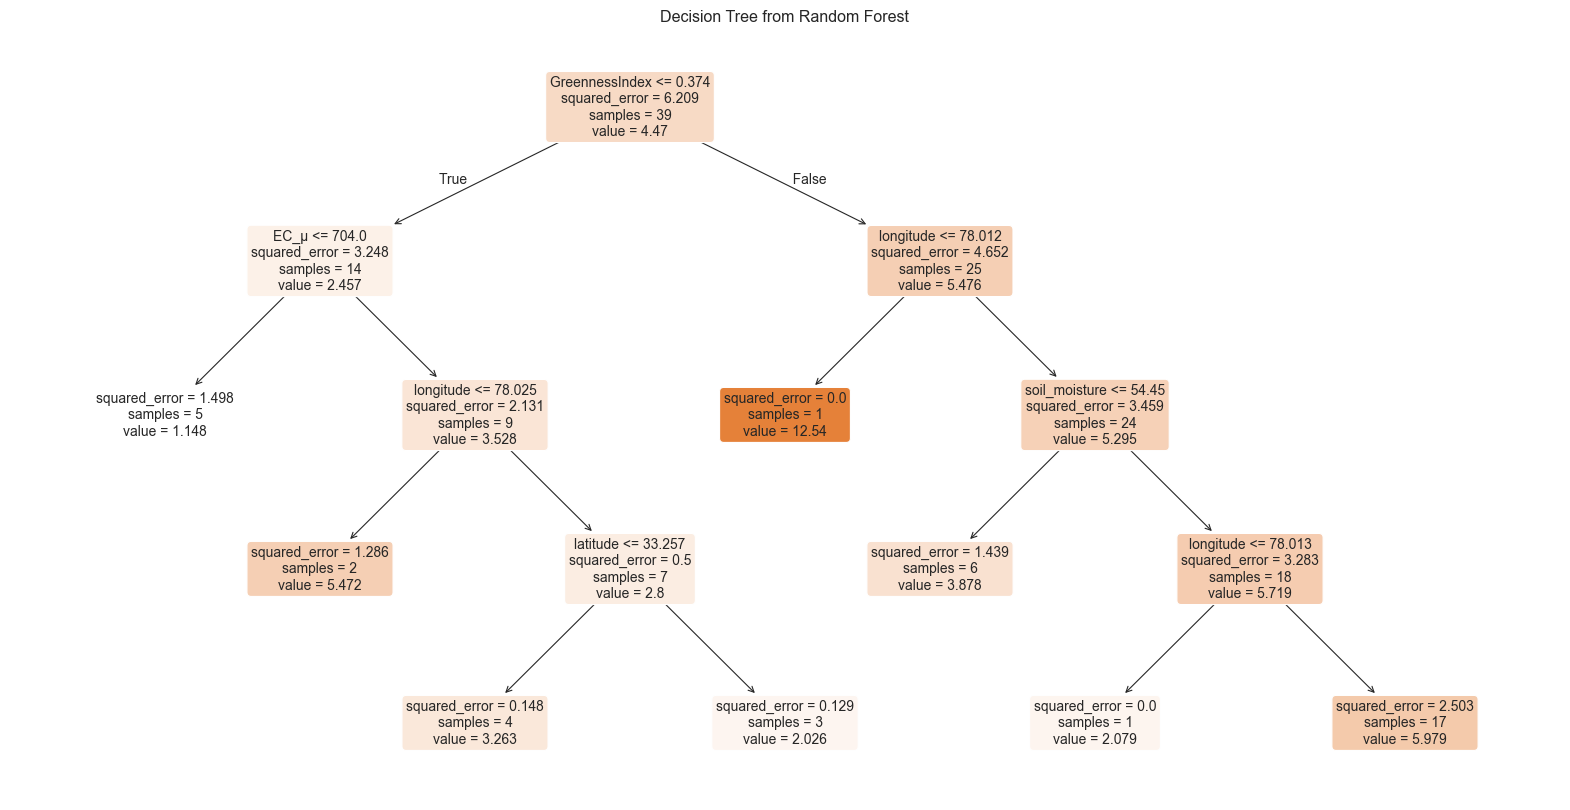

In [32]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_to_plot = best_model1.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(tree_to_plot, feature_names=X_train1.columns, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree from Random Forest")
plt.show()